# VGG-16 Model

## Import Libraries and Set Configurations

In [1]:
# Import the relevant libraries
from utils.seed_utils import *
from utils.data_utils import *
from utils.training_evaluation_utils import *
from utils.external_validation_utils import *
from utils.cache_utils import *
from utils.results_utils import *
from utils.experiment_runner import (run_single_experiment as shared_run_single_experiment)

import os
import json
import copy
import numpy as np
import pandas as pd
import torch.optim as optim
import torch
import torch.nn as nn
from functools import partial

from sklearn.utils.class_weight import compute_class_weight
from torchvision import models
from torchvision.models import VGG16_Weights

import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader

In [2]:
# List the configurations
DATA_DIR = "../data/EBHI-SEG"

BATCH_SIZE = 32
NUM_WORKERS = 0
IMAGE_SIZE = 224
NUM_EPOCHS_STAGE1 = 15
NUM_EPOCHS_STAGE2 = 25

LR_STAGE1 = 1e-3
LR_STAGE2 = 3e-5

WEIGHT_DECAY = 1e-4
PATIENCE = 5
LABEL_SMOOTHING = 0.05

## Multi-Run Configuration

In [3]:
# Multi-run configuration
SPLIT_SEED = 42
RUN_SEEDS = [42, 123, 2024, 3407, 9999, 7, 77, 314, 2025, 8888]
N_RUNS = len(RUN_SEEDS)
CACHE_DIR = "outputs/vgg16/run_cache"
RESULTS_DIR = "outputs/vgg16"
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

SAVE_MODEL_PER_RUN = True
if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("Using device:", DEVICE)
print(f"Planned runs: {N_RUNS} (seeds {RUN_SEEDS})")

Using device: mps
Planned runs: 10 (seeds [42, 123, 2024, 3407, 9999, 7, 77, 314, 2025, 8888])


## Caching Functions

In [4]:
# Configure shared caching functions for this architecture
run_cache_path = partial(run_cache_path, cache_dir=CACHE_DIR)
run_model_path = partial(run_model_path, cache_dir=CACHE_DIR)
load_cached_run = partial(load_cached_run, cache_dir=CACHE_DIR)
save_run_cache = partial(save_run_cache, cache_dir=CACHE_DIR)

## Building the VGG-16 Model

In [5]:
# Function to build the VGG16 model
def build_vgg16(num_classes):
    weights = VGG16_Weights.DEFAULT
    model = models.vgg16(weights=weights)
    # Replace VGG16 classifier
    model.classifier = nn.Sequential(
        nn.Linear(25088, 512),
        nn.BatchNorm1d(512),
        nn.ReLU(),
        nn.Dropout(0.5),

        nn.Linear(512, 128),
        nn.BatchNorm1d(128),
        nn.ReLU(),
        nn.Dropout(0.4),

        nn.Linear(128, num_classes)
    )

    return model

# Function to freeze the backbone
def freeze_backbone(model):
    for param in model.parameters():
        param.requires_grad = False
    for param in model.classifier.parameters():
        param.requires_grad = True

# Function to unfreeze for finetuning
def unfreeze_for_finetuning(model):
    for param in model.parameters():
        param.requires_grad = False
    # Train classifier
    for param in model.classifier.parameters():
        param.requires_grad = True
    # Fine-tune last VGG feature layers
    for param in model.features[24:].parameters():
        param.requires_grad = True

## External Validation Configuration

In [6]:
EXTERNAL_DIR = "../data/lung_colon_image_set/Test Set"
EXTERNAL_IMAGE_SIZE = 224
EXTERNAL_BATCH_SIZE = 16
EXTERNAL_NUM_WORKERS = 0

external_class_names = [
    "Adenocarcinoma",
    "High-grade IN",
    "Low-grade IN",
    "Normal",
    "Polyp",
    "Serrated adenoma"
]
external_class_to_index = {cls: i for i, cls in enumerate(external_class_names)}

external_label_map = {
    "colon_aca": "Adenocarcinoma",
    "colon_n": "Normal"
}

external_labels = [external_class_to_index[c] for c in external_label_map.values()]
external_target_names = list(external_label_map.values())

## Single-Run Experiment

In [7]:
def run_single_experiment(run_idx, seed):
    return shared_run_single_experiment(
        run_idx=run_idx,
        seed=seed,

        # Architecture-specific configuration
        model_name="VGG-16",
        build_model=build_vgg16,
        freeze_backbone=freeze_backbone,
        unfreeze_for_finetuning=unfreeze_for_finetuning,

        # Dataset and preprocessing
        data_dir=DATA_DIR,
        split_seed=SPLIT_SEED,
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS,
        device=DEVICE,

        # Training configuration
        label_smoothing=LABEL_SMOOTHING,
        lr_stage1=LR_STAGE1,
        lr_stage2=LR_STAGE2,
        weight_decay=WEIGHT_DECAY,
        num_epochs_stage1=NUM_EPOCHS_STAGE1,
        num_epochs_stage2=NUM_EPOCHS_STAGE2,
        patience=PATIENCE,

        # External validation
        external_dir=EXTERNAL_DIR,
        external_label_map=external_label_map,
        external_class_to_index=external_class_to_index,
        external_image_size=EXTERNAL_IMAGE_SIZE,
        external_batch_size=EXTERNAL_BATCH_SIZE,
        external_num_workers=EXTERNAL_NUM_WORKERS,
        external_labels=external_labels,
        external_target_names=external_target_names,
        external_class_names=external_class_names,

        # Checkpoint saving
        save_model_per_run=SAVE_MODEL_PER_RUN,
        model_path_fn=run_model_path,
    )


## Run a Single Experiment (with caching)

In [8]:
# Configure the shared run-or-load function
run_or_load = partial(
    run_or_load,
    cache_dir=CACHE_DIR,
    run_single_experiment=run_single_experiment
)

## Execute All Runs

Runs (or loads from cache) each of the `N_RUNS` repetitions in sequence.

In [9]:
all_run_results = []

for i, seed in enumerate(RUN_SEEDS):
    result = run_or_load(i, seed)
    all_run_results.append(result)

print(f"\nCollected {len(all_run_results)} / {N_RUNS} runs.")

[cache] Run 0 (seed=42) already cached — skipping training.
[cache] Run 1 (seed=123) already cached — skipping training.
[cache] Run 2 (seed=2024) already cached — skipping training.
[cache] Run 3 (seed=3407) already cached — skipping training.
[cache] Run 4 (seed=9999) already cached — skipping training.
[cache] Run 5 (seed=7) already cached — skipping training.
[cache] Run 6 (seed=77) already cached — skipping training.
[cache] Run 7 (seed=314) already cached — skipping training.
[cache] Run 8 (seed=2025) already cached — skipping training.
[cache] Run 9 (seed=8888) already cached — skipping training.

Collected 10 / 10 runs.


## Aggregate Results: Mean ± SD

In [10]:
sections = {
    "Internal Test (Normal, no TTA)": "internal_normal",
    "Internal Test (TTA)": "internal_tta",
    "External Validation (Normal, no TTA)": "external_normal",
    "External Validation (TTA)": "external_tta",
}

summary_tables = {}

for title, key in sections.items():
    df = aggregate_section(all_run_results, key)
    summary_tables[key] = df

    print("\n" + "=" * 70)
    print(title, f"(n={len(all_run_results)} runs)")
    print("=" * 70)

    if df.empty:
        print("No numeric metrics found for this section.")
    else:
        print(df[["metric", "mean_pm_sd"]].to_string(index=False))


Internal Test (Normal, no TTA) (n=10 runs)
          metric      mean_pm_sd
        accuracy 0.8818 ± 0.0155
        f1_macro 0.8075 ± 0.0296
            loss 0.9321 ± 0.0272
   macro_roc_auc 0.9731 ± 0.0067
 precision_macro 0.7995 ± 0.0413
    recall_macro 0.8238 ± 0.0173
weighted_roc_auc 0.9831 ± 0.0024

Internal Test (TTA) (n=10 runs)
          metric      mean_pm_sd
        accuracy 0.8988 ± 0.0114
        f1_macro 0.8356 ± 0.0182
            loss 1.0168 ± 0.0191
   macro_roc_auc 0.9802 ± 0.0029
 precision_macro 0.8210 ± 0.0229
    recall_macro 0.8587 ± 0.0216
weighted_roc_auc 0.9861 ± 0.0013

External Validation (Normal, no TTA) (n=10 runs)
   metric      mean_pm_sd
 accuracy 0.7785 ± 0.0314
 macro_f1 0.8085 ± 0.0323
precision 0.8589 ± 0.0176
   recall 0.7785 ± 0.0314

External Validation (TTA) (n=10 runs)
   metric      mean_pm_sd
 accuracy 0.8082 ± 0.0292
 macro_f1 0.8414 ± 0.0244
precision 0.8884 ± 0.0182
   recall 0.8082 ± 0.0292


## Save Aggregated Summary and Per-Run Table
- `vgg16_multirun_summary.json`: mean/SD for every metric, per section
- `vgg16_multirun_per_run.csv`: the raw per-run scalar metrics (one row per run) for full transparency
- Each individual run's full result is also available in`outputs/vgg16/run_cache/`

In [11]:
# Save mean +/- SD summary
summary_json = {
    title: df.to_dict(orient="records")
    for title, df in zip(sections.keys(), summary_tables.values())
}
summary_json["n_runs"] = len(all_run_results)
summary_json["seeds"] = [r["seed"] for r in all_run_results]

summary_path = os.path.join(RESULTS_DIR, "vgg16_multirun_summary.json")
with open(summary_path, "w") as f:
    json.dump(summary_json, f, indent=2)
print("Saved aggregated summary to:", summary_path)

# Save a flat per-run CSV for transparency / re-analysis
per_run_rows = []
for r in all_run_results:
    row = {"run_idx": r["run_idx"], "seed": r["seed"]}
    for section_key in ["internal_normal", "internal_tta", "external_normal", "external_tta"]:
        if section_key in r:
            for k, v in flatten_numeric(r[section_key]).items():
                row[f"{section_key}.{k}"] = v
    per_run_rows.append(row)

per_run_df = pd.DataFrame(per_run_rows)
per_run_csv_path = os.path.join(RESULTS_DIR, "vgg16_multirun_per_run.csv")
per_run_df.to_csv(per_run_csv_path, index=False)
print("Saved per-run metrics to:", per_run_csv_path)

per_run_df

Saved aggregated summary to: outputs/vgg16/vgg16_multirun_summary.json
Saved per-run metrics to: outputs/vgg16/vgg16_multirun_per_run.csv


,run_idx,seed,internal_normal.loss,internal_normal.accuracy,internal_normal.precision_macro,internal_normal.recall_macro,internal_normal.f1_macro,internal_normal.macro_roc_auc,internal_normal.weighted_roc_auc,internal_tta.loss,...,internal_tta.macro_roc_auc,internal_tta.weighted_roc_auc,external_normal.accuracy,external_normal.precision,external_normal.recall,external_normal.macro_f1,external_tta.accuracy,external_tta.precision,external_tta.recall,external_tta.macro_f1
0,0,42,0.910774,0.904478,0.848278,0.846249,0.845648,0.979421,0.986282,0.996966,...,0.981253,0.987338,0.760,0.856598,0.760,0.800249,0.797,0.896099,0.797,0.841687
1,1,123,0.929834,0.886567,0.791940,0.833616,0.809182,0.971142,0.983136,1.009939,...,0.974656,0.984170,0.798,0.870584,0.798,0.831019,0.849,0.901291,0.849,0.873725
2,2,2024,0.993379,0.865672,0.758504,0.794663,0.774624,0.958954,0.977747,1.029249,...,0.980862,0.985632,0.765,0.851849,0.765,0.806083,0.797,0.884483,0.797,0.838459
3,3,3407,0.906346,0.892537,0.833973,0.839917,0.835160,0.978708,0.984693,1.008934,...,0.981197,0.987430,0.818,0.872208,0.818,0.843284,0.818,0.881364,0.818,0.848485
4,4,9999,0.922230,0.880597,0.819163,0.843373,0.830234,0.973781,0.982428,1.009543,...,0.983627,0.987230,0.787,0.857543,0.787,0.812653,0.823,0.881882,0.823,0.849228
5,5,7,0.924801,0.892537,0.818539,0.817330,0.815016,0.968776,0.983917,0.994677,...,0.975256,0.985404,0.801,0.854807,0.801,0.827027,0.834,0.885312,0.834,0.858887
6,6,77,0.912461,0.886567,0.812321,0.804848,0.806468,0.978148,0.985005,1.006301,...,0.981049,0.987226,0.776,0.851572,0.776,0.811602,0.806,0.879649,0.806,0.839458
7,7,314,0.964952,0.889552,0.834685,0.828475,0.825354,0.966580,0.981187,1.024955,...,0.981214,0.986154,0.738,0.822618,0.738,0.775847,0.763,0.850295,0.763,0.802054
8,8,2025,0.920480,0.853731,0.722144,0.812191,0.753610,0.978676,0.983715,1.058647,...,0.979918,0.983770,0.726,0.859781,0.726,0.736530,0.762,0.908771,0.762,0.798674
9,9,8888,0.935607,0.865672,0.755583,0.817829,0.779242,0.976731,0.983224,1.028675,...,0.982807,0.986904,0.816,0.891113,0.816,0.840237,0.833,0.914577,0.833,0.863795


## Confusion Matrix for a Single Reference Run

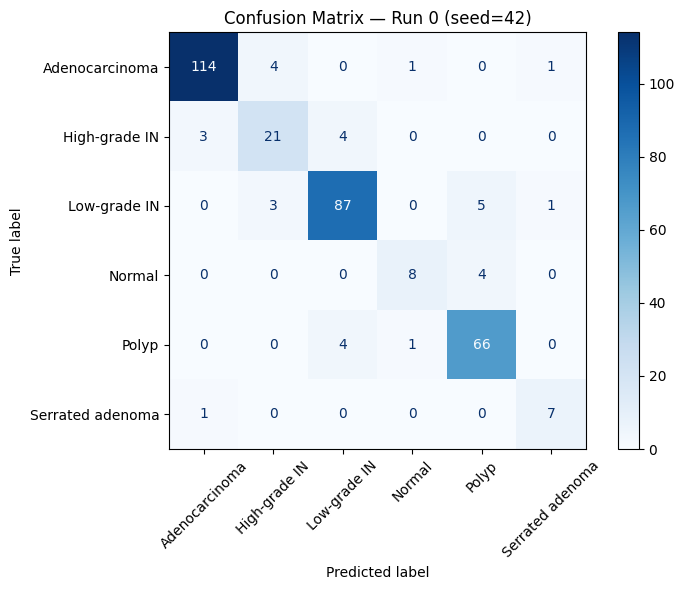

In [12]:
reference_run = all_run_results[0]

cm_ref = np.array(reference_run["internal_normal_extra"]["confusion_matrix"])
display = ConfusionMatrixDisplay(
    confusion_matrix=cm_ref,
    display_labels=reference_run["class_names"]
)
fig, ax = plt.subplots(figsize=(8, 6))
display.plot(cmap="Blues", ax=ax, values_format="d")
plt.title(f"Confusion Matrix — Run {reference_run['run_idx']} (seed={reference_run['seed']})")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()